# Tech Challenge Olist — Desempenho e Sazonalidade
**Pergunta Norteadora 1** · Análise de 2017 a 2018 · Notebook com a paleta visual FIAP

### Navegação
1. **Carregamento e inspeção** — importação dos arquivos e conferências iniciais
2. **Preparação analítica** — base de pedidos entregues
3. **Análise exploratória** — estatística e distribuição dos valores
4. **Indicadores mensais** — faturamento, pedidos, ticket médio e estabilidade
5. **Visualizações** — trajetória, comparação, sazonalidade e perfil normalizado
6. **Exportação** — gráficos e tabelas

> **Nota:** Mantidos os cálculos, os critérios de análise, a organização e a paleta FIAP; a base analítica foi limitada a pedidos entregues comprados em 2017 e 2018, excluindo 2016.

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
import io

print("Arquivo tratado")
upload = files.upload()
arquivos_zip = [nome for nome in upload if nome.lower().endswith(".zip")]
if len(arquivos_zip) != 1:
    raise ValueError("ZIP: olist_bases_tratadas.zip")
caminho_zip = arquivos_zip[0]
with zipfile.ZipFile(caminho_zip) as z:
    nomes = z.namelist()
print(f"ZIP recebido: {caminho_zip} | {len(nomes)} arquivos")
print("\n".join(nomes))

Arquivo tratado


Saving olist_bases_tratadas.zip to olist_bases_tratadas.zip
ZIP recebido: olist_bases_tratadas.zip | 16 arquivos
derivada_geolocation_consulta_unica.csv
dicionario_dados_olist.csv
integrada_items_products_sellers.csv
integrada_orders_customers.csv
integrada_payments_orders.csv
integrada_reviews_orders.csv
olist_customers_tratado.csv
olist_geolocation_tratado.csv
olist_order_items_tratado.csv
olist_order_payments_tratado.csv
olist_order_reviews_tratado.csv
olist_orders_tratado.csv
olist_products_tratado.csv
olist_sellers_tratado.csv
product_category_name_translation_tratado.csv
relatorio_qualidade_etl.csv


## 1. Carregamento e inspeção dos dados
### 1.1 Leitura das tabelas tratadas

In [2]:
with zipfile.ZipFile(caminho_zip) as z:
    esperados = ["olist_orders_tratado.csv", "olist_order_items_tratado.csv"]
    faltantes = [nome for nome in esperados if nome not in z.namelist()]
    if faltantes:
        raise FileNotFoundError(f"O ZIP não contém: {faltantes}. Use a exportação do ETL do grupo.")
    pedidos = pd.read_csv(z.open("olist_orders_tratado.csv"))
    itens = pd.read_csv(z.open("olist_order_items_tratado.csv"))

print("Pedidos:", pedidos.shape, "| Itens:", itens.shape)
display(pedidos.head(3))
display(itens.head(3))

Pedidos: (99441, 8) | Itens: (112650, 7)


,id_pedido,id_cliente,status_pedido,data_compra_pedido,data_aprovacao_pedido,data_entrega_transportadora,data_entrega_cliente,data_estimada_entrega
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,id_pedido,id_item_pedido,id_produto,id_vendedor,data_limite_envio,preco,valor_frete
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


### 1.2 Relatório de qualidade do tratamento

In [3]:
with zipfile.ZipFile(caminho_zip) as z:
    qualidade = pd.read_csv(z.open('relatorio_qualidade_etl.csv'))
    print('Arquivos de saída no ZIP:', len(z.namelist()))
    print('Relatório de qualidade:')
    display(qualidade)
    print('Registros de pedidos:',len(pedidos),'| Linhas de itens:',len(itens))
    print('Nulos em preço:',itens['preco'].isna().sum())
    print('IDs de pedido duplicados:',pedidos['id_pedido'].duplicated().sum())

Arquivos de saída no ZIP: 16
Relatório de qualidade:


,Nome da Tabela,Linhas Antes,Linhas Após,Colunas,Valores Nulos,Duplicadas Totais,Correções Codificação,Status Validação,Observações
0,Customers,99441,99441,5,0,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
1,Geolocation,1000163,1000163,5,0,279650,160718,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
2,Order Items,112650,112650,7,0,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
3,Order Reviews,99224,99224,7,145903,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
4,Order Payments,103886,103886,5,0,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
5,Orders,99441,99441,8,4908,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
6,Products,32951,32951,9,2448,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
7,Sellers,3095,3095,4,0,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...
8,Category Translation,71,71,2,0,0,0,Aprovado,Nenhuma exclusão realizada. Nulos/duplicados p...


Registros de pedidos: 99441 | Linhas de itens: 112650
Nulos em preço: 0
IDs de pedido duplicados: 0


### 1.3 Análise exploratória das tabelas (EDA)

In [4]:
def eda_tabela(df, nome):
    print(f"\n===== {nome} =====")
    print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")
    print(f"Duplicadas (linha inteira): {int(df.duplicated().sum()):,}")
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (100*df.isna().mean()).round(2),
        "valores_distintos": df.nunique(dropna=True)
    })
    display(resumo)

eda_tabela(pedidos, "Pedidos tratados")
eda_tabela(itens, "Itens tratados")
print("Status dos pedidos:")
display(pedidos["status_pedido"].value_counts(dropna=False).rename_axis("status").reset_index(name="quantidade"))
print("IDs duplicados em pedidos:", pedidos["id_pedido"].duplicated().sum())
print("IDs de pedidos presentes em itens:", itens["id_pedido"].nunique())


===== Pedidos tratados =====
Linhas: 99,441 | Colunas: 8
Duplicadas (linha inteira): 0


,tipo,nulos,% nulos,valores_distintos
id_pedido,object,0,0.00,99441
id_cliente,object,0,0.00,99441
status_pedido,object,0,0.00,8
data_compra_pedido,object,0,0.00,98875
data_aprovacao_pedido,object,160,0.16,90733
data_entrega_transportadora,object,1783,1.79,81018
data_entrega_cliente,object,2965,2.98,95664
data_estimada_entrega,object,0,0.00,459



===== Itens tratados =====
Linhas: 112,650 | Colunas: 7
Duplicadas (linha inteira): 0


,tipo,nulos,% nulos,valores_distintos
id_pedido,object,0,0.0,98666
id_item_pedido,int64,0,0.0,21
id_produto,object,0,0.0,32951
id_vendedor,object,0,0.0,3095
data_limite_envio,object,0,0.0,93318
preco,float64,0,0.0,5968
valor_frete,float64,0,0.0,6999


Status dos pedidos:


,status,quantidade
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


IDs duplicados em pedidos: 0
IDs de pedidos presentes em itens: 98666


## 2. Preparação analítica
Base de trabalho com pedidos entregues e seus itens, considerando compras realizadas em 2017 e 2018.

In [5]:
pedidos_a = pedidos.copy()
itens_a = itens.copy()
pedidos_a["data_compra_pedido"] = pd.to_datetime(pedidos_a["data_compra_pedido"], errors="coerce")
itens_a["preco"] = pd.to_numeric(itens_a["preco"], errors="coerce")

print("Pedidos sem data válida:", pedidos_a["data_compra_pedido"].isna().sum())
print("Itens com preço ausente/não numérico:", itens_a["preco"].isna().sum())
print("Itens com preço <= 0:", itens_a["preco"].le(0).sum())
if pedidos_a["id_pedido"].duplicated().any():
    raise ValueError("Existe ID duplicado em pedidos. Verifique o ETL antes de prosseguir.")

soma_itens = (itens_a.groupby("id_pedido", as_index=False)
                   .agg(valor_produtos=("preco", "sum"),
                        quantidade_itens=("preco", "size")))
entregues = pedidos_a.loc[pedidos_a["status_pedido"].eq("delivered") & pedidos_a["data_compra_pedido"].dt.year.isin([2017, 2018])].copy()
base = entregues.merge(soma_itens, on="id_pedido", how="left", validate="one_to_one")
print("Pedidos entregues:", len(entregues))
print("Pedidos entregues sem itens:", int(base["valor_produtos"].isna().sum()))
base = base.dropna(subset=["data_compra_pedido", "valor_produtos"]).copy()
base["mes"] = base["data_compra_pedido"].dt.to_period("M").dt.to_timestamp()
base["ano"] = base["data_compra_pedido"].dt.year
base["mes_num"] = base["data_compra_pedido"].dt.month
base["dia"] = base["data_compra_pedido"].dt.normalize()
base["dia_semana"] = base["data_compra_pedido"].dt.dayofweek
print("Base final em nível de pedido:", base.shape)
print("Menor e maior data:", base["data_compra_pedido"].min(),base["data_compra_pedido"].max())

Pedidos sem data válida: 0
Itens com preço ausente/não numérico: 0
Itens com preço <= 0: 0
Pedidos entregues: 96211
Pedidos entregues sem itens: 0
Base final em nível de pedido: (96211, 15)
Menor e maior data: 2017-01-05 11:56:06 2018-08-29 15:00:37


## 3. Distribuição dos valores por pedido
Estatística descritiva e histograma.

Faturamento total dos pedidos entregues (2017–2018): R$ 13,181,027.13
Pedidos com valor de produtos: 96211


,Valor R$ por pedido
count,96211.000000
mean,137.001249
std,209.113370
min,0.850000
25%,45.900000
50%,86.500000
75%,149.900000
90%,269.000000
99%,991.710000
max,13440.000000


Limite superior do IQR: R$ 305.90
Pedidos acima do limite: 7,627 (7.93% dos pedidos)
Participação no faturamento: 36.60%


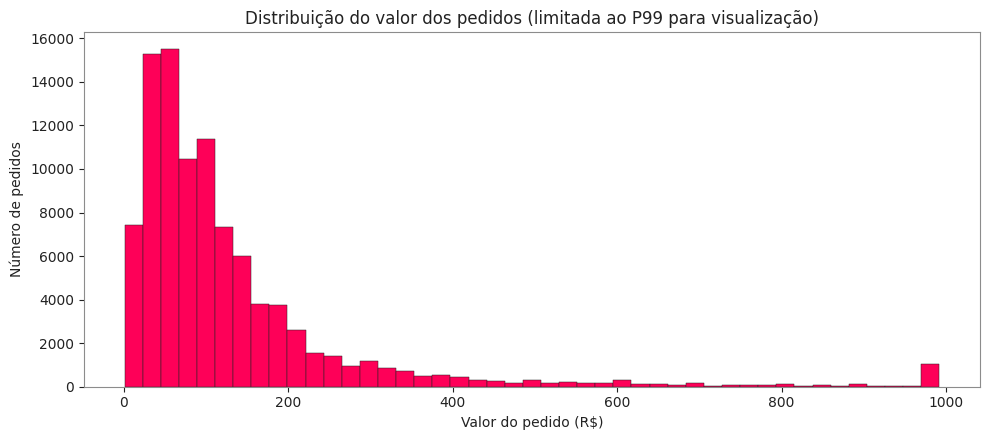

In [6]:
print("Faturamento total dos pedidos entregues (2017–2018): R$",f"{base['valor_produtos'].sum():,.2f}")
print("Pedidos com valor de produtos:",len(base))
descricao = base["valor_produtos"].describe(percentiles=[.25,.5,.75,.9,.99]).rename("Valor R$ por pedido")
display(descricao.to_frame())
q1,q3=base["valor_produtos"].quantile([.25,.75])
iqr=q3-q1
limite=q3+1.5*iqr
outliers=base["valor_produtos"]>limite
print(f"Limite superior do IQR: R$ {limite:,.2f}")
print(f"Pedidos acima do limite: {outliers.sum():,} ({100*outliers.mean():.2f}% dos pedidos)")
print(f"Participação no faturamento: {100*base.loc[outliers,'valor_produtos'].sum()/base['valor_produtos'].sum():.2f}%")
# Paleta visual FIAP — apenas cores dos gráficos
ROSA = "#FE0058"
ROSA_ESCURO = "#A3003A"
ROSA_CLARO = "#FF8AB0"
GRAFITE = "#222222"
CINZA = "#8C8C8C"
plt.rcParams.update({
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#FFFFFF",
    "savefig.facecolor": "#FFFFFF",
    "text.color": GRAFITE,
    "axes.labelcolor": GRAFITE,
    "axes.edgecolor": CINZA,
    "xtick.color": GRAFITE,
    "ytick.color": GRAFITE,
    "grid.color": CINZA,
    "axes.prop_cycle": plt.cycler(color=[ROSA, GRAFITE, ROSA_CLARO, ROSA_ESCURO, CINZA]),
})
plt.figure(figsize=(10,4.5))
plt.hist(base["valor_produtos"].clip(upper=base["valor_produtos"].quantile(.99)),bins=45,color=ROSA,edgecolor=GRAFITE,linewidth=.35)
plt.title("Distribuição do valor dos pedidos (limitada ao P99 para visualização)")
plt.xlabel("Valor do pedido (R$)");plt.ylabel("Número de pedidos")
plt.tight_layout();plt.show()

Indicadores mensais e estatística de estabilidade
O CV = desvio-padrão / média. Como a série de 2017 cresce rapidamente a partir de base baixa, um CV menor em 2018 não comprova por si só causalidade ou previsibilidade futura.

## 4. Indicadores mensais
Faturamento, volume de pedidos, ticket médio e medidas de estabilidade.

In [7]:
mensal=(base.groupby("mes",as_index=False)
        .agg(faturamento=("valor_produtos","sum"),
             pedidos=("id_pedido","nunique")))
mensal["ticket_medio"]=mensal["faturamento"]/mensal["pedidos"]
mensal=mensal.sort_values("mes").reset_index(drop=True)
mensal["variacao_mensal_pct"]=mensal["faturamento"].pct_change()*100
serie=mensal[mensal["mes"].between("2017-01-01","2018-07-01")].copy()
serie["variacao_mensal_pct"] = serie["faturamento"].pct_change() * 100
display(serie)
comp=base[base["ano"].isin([2017,2018])&base["mes_num"].between(1,7)]
resumo_anos=(comp.groupby("ano")
             .agg(faturamento=("valor_produtos","sum"),pedidos=("id_pedido","nunique")))
resumo_anos["ticket_medio"]=resumo_anos["faturamento"]/resumo_anos["pedidos"]
print("Comparação justa entre janeiro e julho de 2017 e 2018:")
display(resumo_anos)
for col in ["faturamento","pedidos","ticket_medio"]:
    if 2017 in resumo_anos.index and 2018 in resumo_anos.index:
        print(f"Variação de {col}: {(resumo_anos.loc[2018,col]/resumo_anos.loc[2017,col]-1)*100:.2f}%")
estabilidade=(serie.assign(ano=serie["mes"].dt.year, mes_num=serie["mes"].dt.month)
             .query("mes_num <= 7")
             .groupby("ano")["faturamento"]
             .agg(["count","mean","median","std","min","max"]))
estabilidade["cv_pct"]=100*estabilidade["std"]/estabilidade["mean"]
print("Estatística descritiva dos meses jan-jul:")
display(estabilidade)

,mes,faturamento,pedidos,ticket_medio,variacao_mensal_pct
0,2017-01-01,111798.36,750,149.064480,NaN
1,2017-02-01,234223.40,1653,141.695947,109.505220
2,2017-03-01,359198.85,2546,141.083602,53.357372
3,2017-04-01,340669.68,2303,147.924307,-5.158471
4,2017-05-01,489338.25,3546,137.997250,43.640094
5,2017-06-01,421923.37,3135,134.584807,-13.776744
6,2017-07-01,481604.52,3872,124.381333,14.145021
7,2017-08-01,554699.70,4193,132.291844,15.177428
8,2017-09-01,607399.67,4150,146.361366,9.500631
9,2017-10-01,648247.65,4478,144.762762,6.725058


Comparação justa entre janeiro e julho de 2017 e 2018:


,faturamento,pedidos,ticket_medio
ano,,,
2017,2438756.43,17805,136.970313
2018,6379548.48,46432,137.395513


Variação de faturamento: 161.59%
Variação de pedidos: 160.78%
Variação de ticket_medio: 0.31%
Estatística descritiva dos meses jan-jul:


,count,mean,median,std,min,max,cv_pct
ano,,,,,,,
2017,7,348393.775714,359198.85,136751.432152,111798.36,489338.25,39.251973
2018,7,911364.068571,924645.00,61016.860167,826437.13,977544.69,6.695114


## 5. Visualizações
### 5.1 Trajetória mensal e comparação entre 2017 e 2018

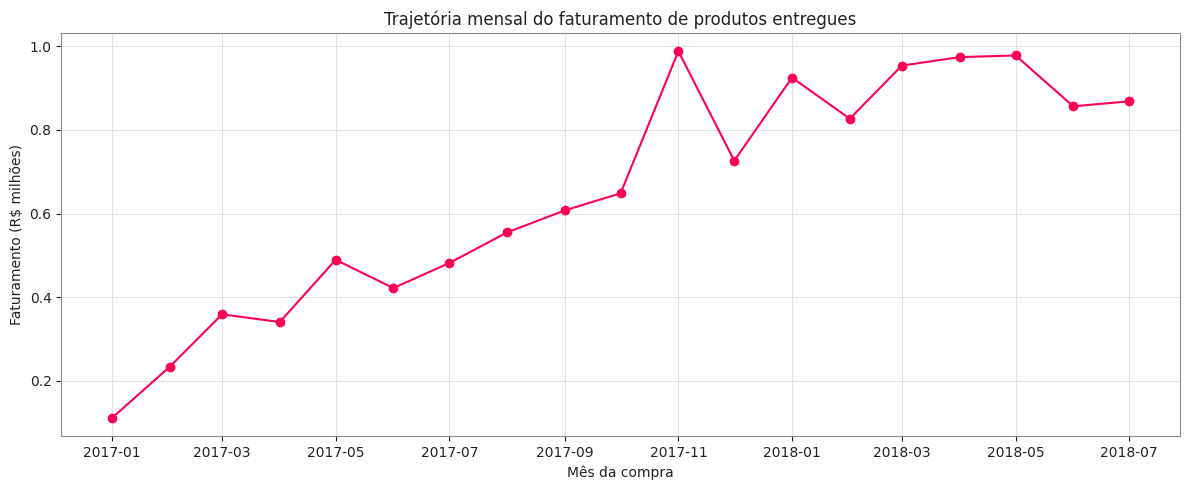

In [8]:
saida=Path("/content/olist_graficos_base_tratada");saida.mkdir(exist_ok=True)
def salvar(nome):
    plt.tight_layout();plt.savefig(saida/nome,dpi=170,bbox_inches="tight");plt.show()

plt.figure(figsize=(12,5))
plt.plot(serie["mes"],serie["faturamento"]/1e6,marker="o",color=ROSA)
plt.title("Trajetória mensal do faturamento de produtos entregues")
plt.xlabel("Mês da compra");plt.ylabel("Faturamento (R$ milhões)");plt.grid(alpha=.25)
salvar("01_trajetoria_mensal.png")



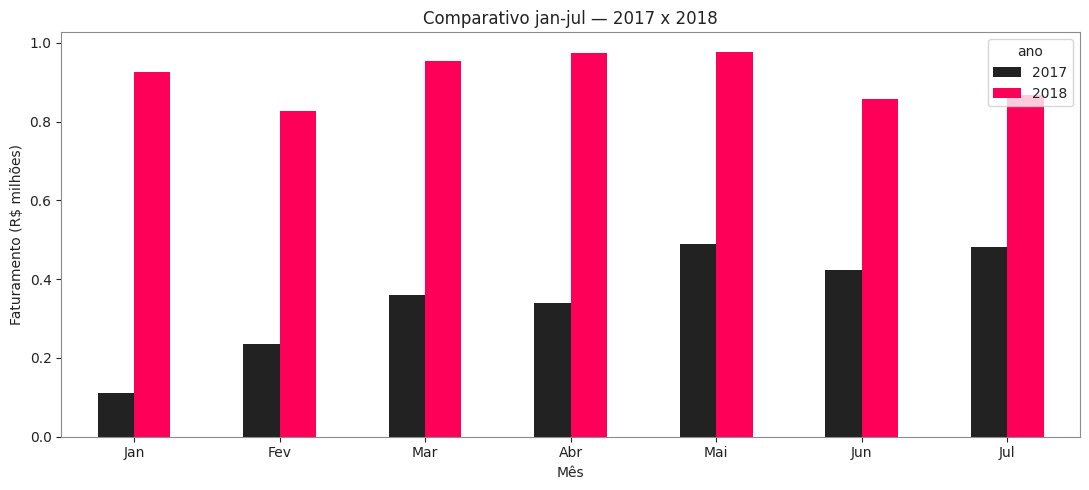

In [9]:
c=serie.assign(ano=serie.mes.dt.year,mes_num=serie.mes.dt.month).query("mes_num <= 7")
p=c.pivot(index="mes_num",columns="ano",values="faturamento")/1e6
ax=p.plot(kind="bar",figsize=(11,5),color=[GRAFITE,ROSA])
ax.set_title("Comparativo jan-jul — 2017 x 2018")
ax.set_xlabel("Mês");ax.set_ylabel("Faturamento (R$ milhões)")
ax.set_xticklabels(["Jan","Fev","Mar","Abr","Mai","Jun","Jul"],rotation=0)
salvar("02_comparacao_anual.png")

### 5.2 Quantidade de pedidos, ticket médio e variação mensal

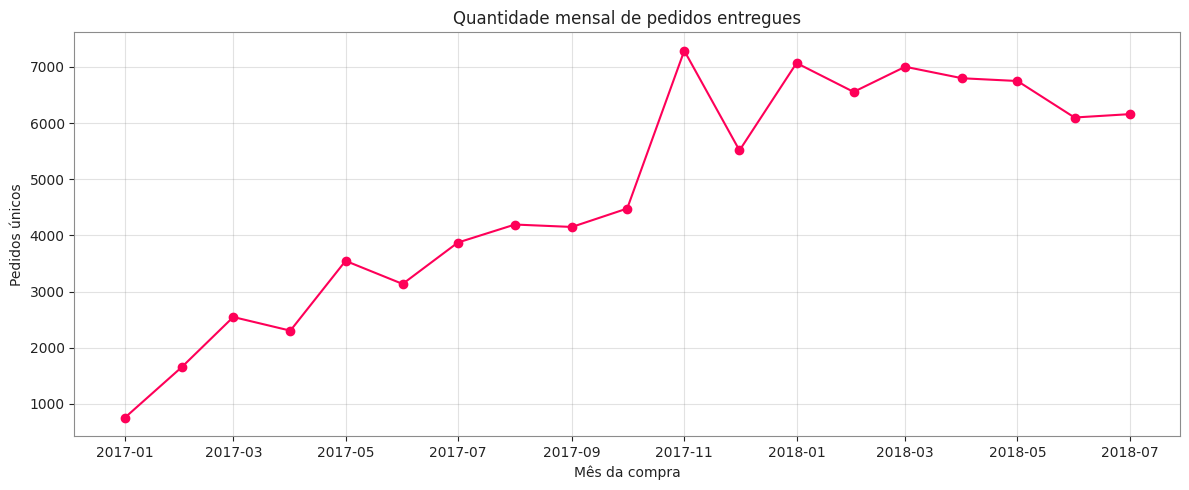

In [10]:
plt.figure(figsize=(12,5))
plt.plot(serie["mes"],serie["pedidos"],marker="o",color=ROSA)
plt.title("Quantidade mensal de pedidos entregues")
plt.xlabel("Mês da compra");plt.ylabel("Pedidos únicos");plt.grid(alpha=.25)
salvar("03_pedidos_mensais.png")





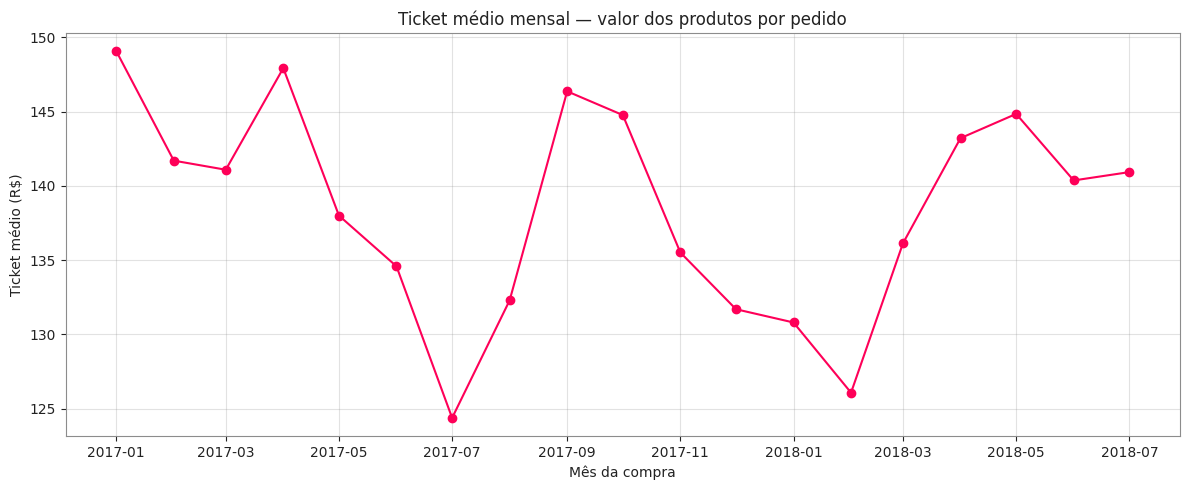

In [11]:
plt.figure(figsize=(12,5))
plt.plot(serie["mes"],serie["ticket_medio"],marker="o",color=ROSA)
plt.title("Ticket médio mensal — valor dos produtos por pedido")
plt.xlabel("Mês da compra");plt.ylabel("Ticket médio (R$)");plt.grid(alpha=.25)
salvar("04_ticket_medio.png")

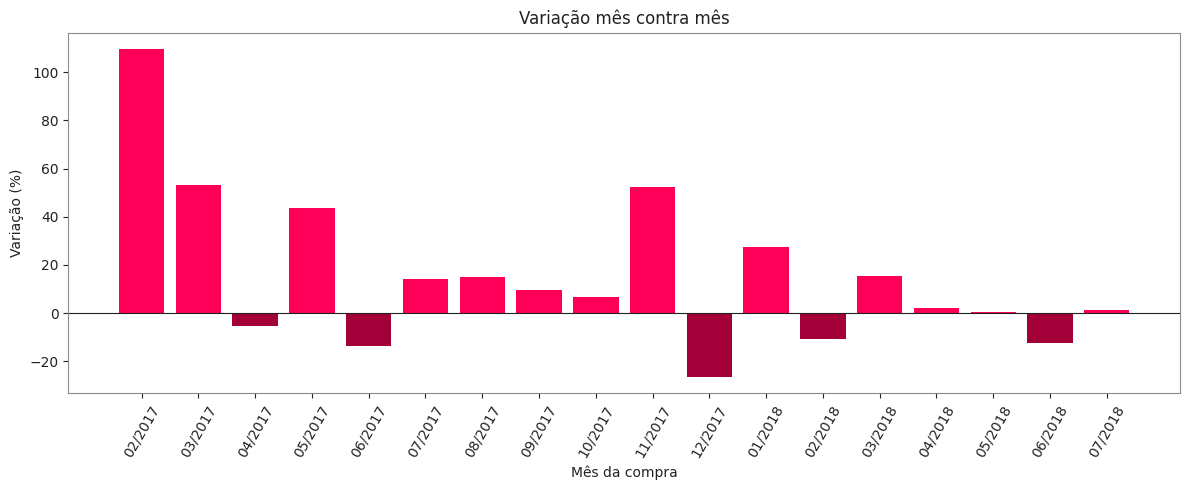

In [12]:
v=serie.dropna(subset=["variacao_mensal_pct"])
plt.figure(figsize=(12,5))
plt.bar(v["mes"].dt.strftime("%m/%Y"),v["variacao_mensal_pct"],color=[ROSA if x >= 0 else ROSA_ESCURO for x in v["variacao_mensal_pct"]])
plt.axhline(0,color=GRAFITE,linewidth=.8)
plt.xticks(rotation=60);plt.title("Variação mês contra mês")
plt.ylabel("Variação (%)");plt.xlabel("Mês da compra")
salvar("05_variacao_mensal.png")

### 5.3 Faturamento no fim de 2017 e Black Friday

Faturamento de outubro a dezembro de 2017:


,mes,faturamento,pedidos,ticket_medio,variacao_mensal_pct
9,2017-10-01,648247.65,4478,144.762762,6.725058
10,2017-11-01,987765.37,7289,135.514525,52.374694
11,2017-12-01,726033.19,5513,131.694756,-26.497404


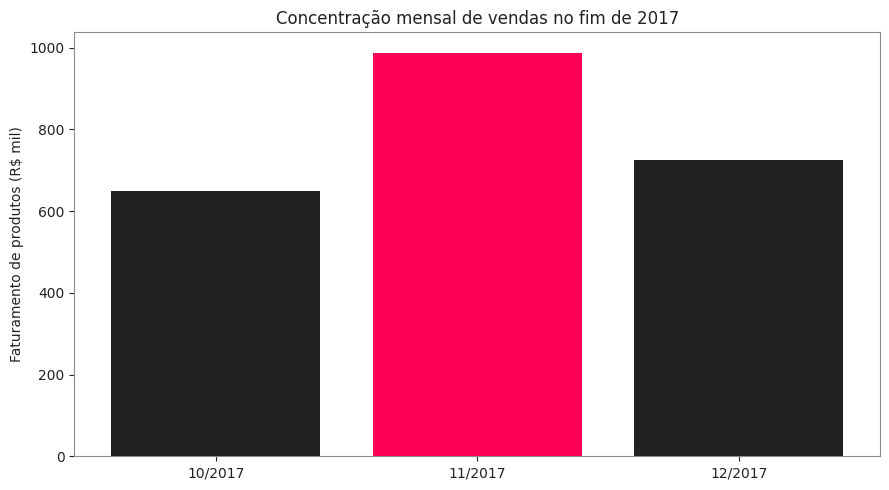

In [13]:
tri=mensal[mensal["mes"].between("2017-10-01","2017-12-01")].copy()
print("Faturamento de outubro a dezembro de 2017:")
display(tri)
plt.figure(figsize=(9,5))
plt.bar(tri["mes"].dt.strftime("%m/%Y"),tri["faturamento"]/1000,color=[GRAFITE,ROSA,GRAFITE])
plt.title("Concentração mensal de vendas no fim de 2017")
plt.ylabel("Faturamento de produtos (R$ mil)")
salvar("06_out_nov_dez_2017.png")



Black Friday 24/11: R$ 149,916.58 | 15.18% de novembro | 6.39 vezes a média das outras sextas-feiras


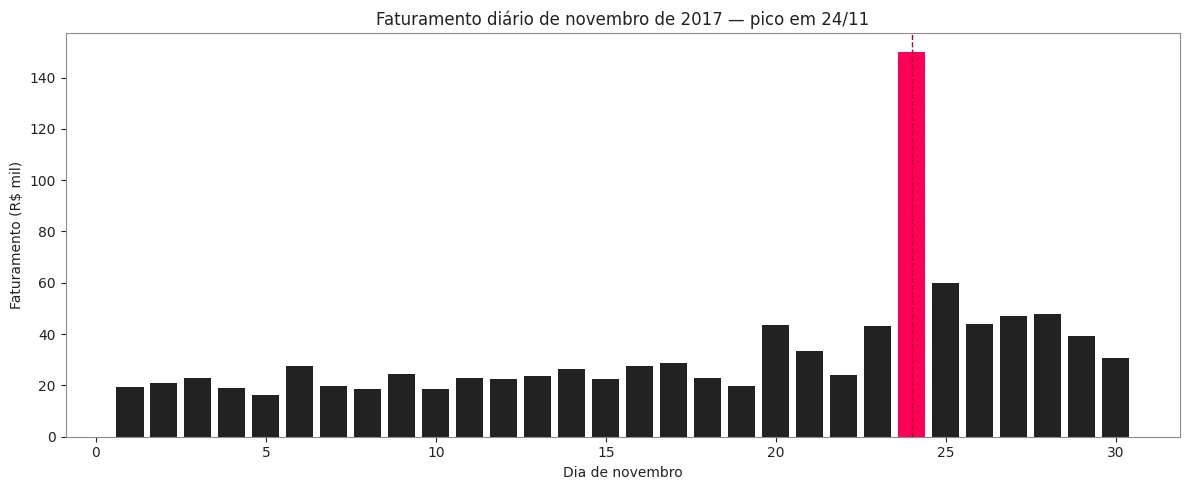

In [14]:
nov=base[(base["dia"] >= "2017-11-01")&(base["dia"] <= "2017-11-30")]
diario=nov.groupby("dia",as_index=False).agg(faturamento=("valor_produtos","sum"),pedidos=("id_pedido","nunique"))
black_friday=pd.Timestamp("2017-11-24")
fat_bf=diario.loc[diario["dia"].eq(black_friday),"faturamento"].sum()
fat_nov=diario["faturamento"].sum()
sextas=diario[diario["dia"].dt.dayofweek.eq(4)]
media_outras=sextas.loc[sextas["dia"].ne(black_friday),"faturamento"].mean()
print(f"Black Friday 24/11: R$ {fat_bf:,.2f} | {100*fat_bf/fat_nov:.2f}% de novembro | {fat_bf/media_outras:.2f} vezes a média das outras sextas-feiras")
plt.figure(figsize=(12,5))
plt.bar(diario["dia"].dt.day,diario["faturamento"]/1000,color=[ROSA if dia == 24 else GRAFITE for dia in diario["dia"].dt.day])
plt.axvline(24,linestyle="--",linewidth=1,color=ROSA_ESCURO)
plt.title("Faturamento diário de novembro de 2017 — pico em 24/11")
plt.xlabel("Dia de novembro");plt.ylabel("Faturamento (R$ mil)")
salvar("07_black_friday_diario.png")

### 5.4 Padrão de faturamento por dia da semana

2017: faturamento médio diário fins de semana = -24.9% versus dias úteis
2018: faturamento médio diário fins de semana = -26.5% versus dias úteis


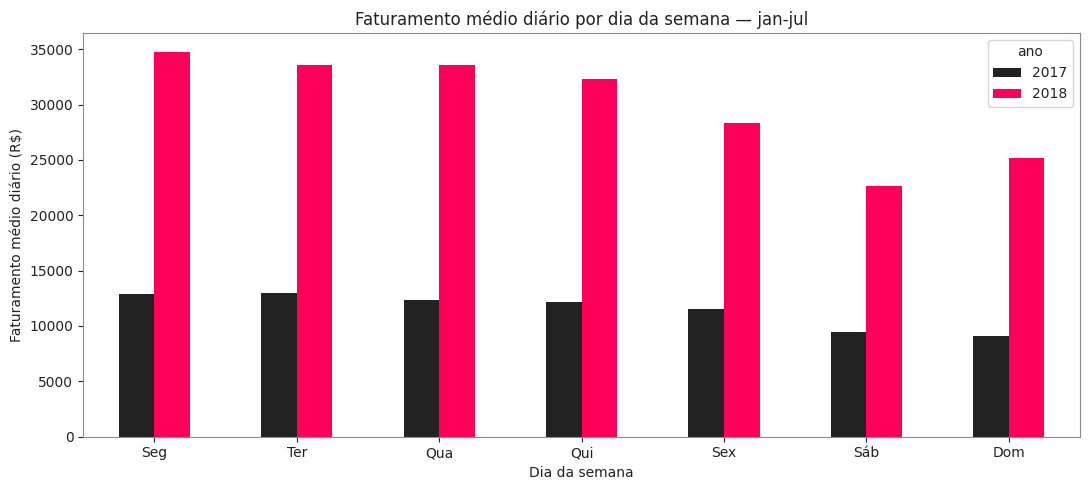

In [15]:
dias_semana=["Seg","Ter","Qua","Qui","Sex","Sáb","Dom"]
linhas=[]
for ano in [2017,2018]:
    inicio=pd.Timestamp(ano,1,1)
    fim=pd.Timestamp(ano,7,31)
    calendario=pd.DataFrame({"dia":pd.date_range(inicio,fim,freq="D")})
    por_dia=base[base["dia"].between(inicio,fim)].groupby("dia")["valor_produtos"].sum().rename("faturamento")
    calendario=calendario.join(por_dia,on="dia").fillna({"faturamento":0})
    calendario["dia_semana"]=calendario["dia"].dt.dayofweek
    media=calendario.groupby("dia_semana")["faturamento"].mean()
    for d,v in media.items():linhas.append({"ano":ano,"dia_semana":d,"faturamento_medio_diario":v})
    uteis=calendario.loc[calendario.dia_semana<=4,"faturamento"].mean()
    fds=calendario.loc[calendario.dia_semana>=5,"faturamento"].mean()
    print(f"{ano}: faturamento médio diário fins de semana = {100*(fds/uteis-1):.1f}% versus dias úteis")
semanal=pd.DataFrame(linhas)
graf=semanal.pivot(index="dia_semana",columns="ano",values="faturamento_medio_diario")
ax=graf.plot(kind="bar",figsize=(11,5),color=[GRAFITE,ROSA])
ax.set_xticklabels(dias_semana,rotation=0)
ax.set_title("Faturamento médio diário por dia da semana — jan-jul")
ax.set_ylabel("Faturamento médio diário (R$)");ax.set_xlabel("Dia da semana")
salvar("08_padrao_semanal.png")

### 5.5 Perfil mensal normalizado

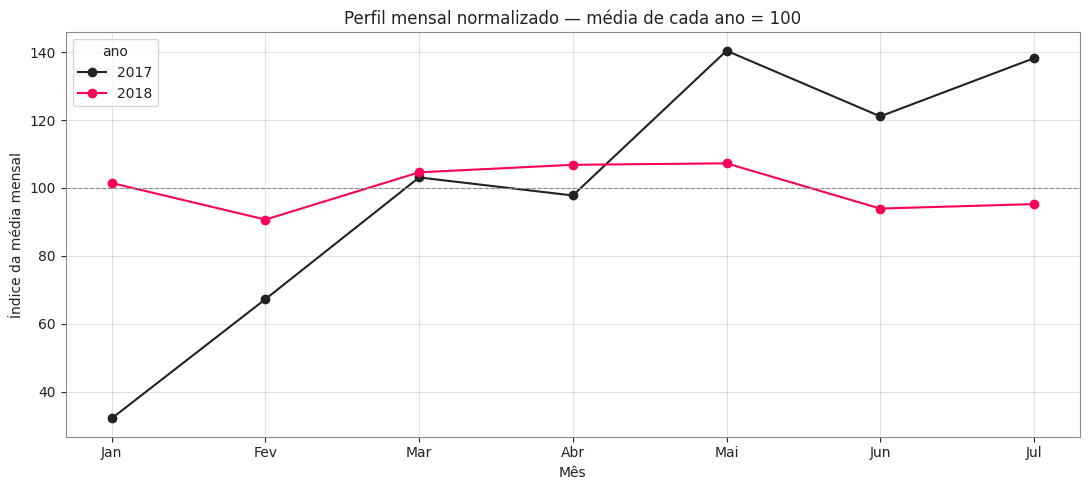

In [16]:
normal=c.copy()
normal["indice"]=(normal["faturamento"] /
                  normal.groupby("ano")["faturamento"].transform("mean")*100)
ax=normal.pivot(index="mes_num",columns="ano",values="indice").plot(marker="o",figsize=(11,5),color=[GRAFITE,ROSA])
ax.axhline(100,linestyle="--",linewidth=.8,color=CINZA)
ax.set_xticks(range(1,8));ax.set_xticklabels(["Jan","Fev","Mar","Abr","Mai","Jun","Jul"])
ax.set_title("Perfil mensal normalizado — média de cada ano = 100")
ax.set_ylabel("Índice da média mensal");ax.set_xlabel("Mês")
ax.grid(alpha=.25)
salvar("09_perfil_mensal_normalizado.png")